# 09. Figures

In [2]:
import sys, os, json
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import src as la
from src import config as cfg, io_utils, evaluation as ev, reporting as rp
cfg.apply_mpl_style(); cfg.banner()
R = cfg.RESULTS
G = cfg.GREYS
NICE = {"P1_naive_random": "P1\nnaive random", "P2_sensor_indep": "P2\nsensor-indep.",
        "P3_site_indep": "P3\nsite-indep.", "P4_site_temporal": "P4\nsite + temporal"}
MODEL_NICE = {"gbdt": "gradient boosting", "rf": "random forest", "logreg": "logistic regression", "mlp": "MLP"}
MARKERS = {"gradient boosting": "o", "random forest": "s", "logistic regression": "^", "MLP": "D"}
MODEL_GREYS = dict(zip(MODEL_NICE.values(), cfg.grey_palette(4)))

def need(path):
    if not (R / path).exists():
        print(f"missing {path} - run the producing notebook first")
        return False
    return True

def bar_centres(ax):
    """x centre and height of every bar patch, in drawing order."""
    return [(p.get_x() + p.get_width() / 2, p.get_height(), p.get_width()) for p in ax.patches
            if p.get_width() > 0]

LeakAudit | root=C:\Users\ecredible\Desktop\LeakAudit_revision1\LeakAudit | mode=FULL | seeds=10 | bootstrap=2000


## Figure 2. D1 five-class accuracy, P1–P4

- Error bars: SD over 10 seeds
- Bars: test-fold majority rate per protocol (mean over seeds)

saved figures/Fig2_D1_protocol_collapse.png and .pdf (600 dpi, greyscale)


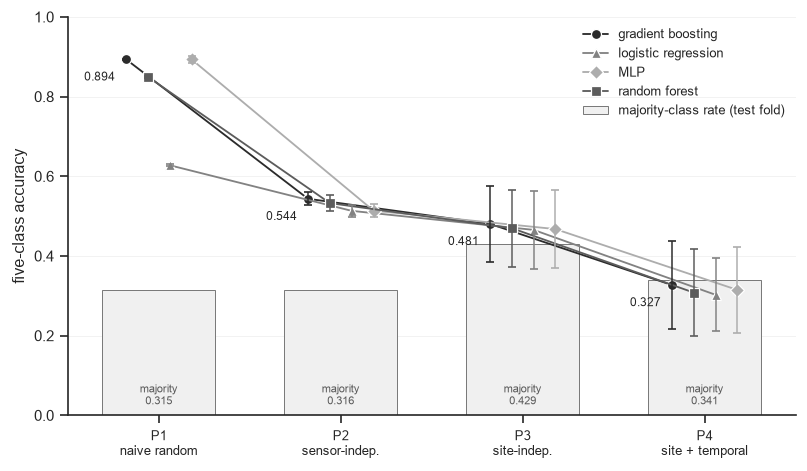

In [3]:
if need("E4_collapse_summary.csv"):
    s4 = pd.read_csv(R / "E4_collapse_summary.csv")
    sub = s4[s4.task == "T5_five_class"].copy()
    sub["model_name"] = sub.model.map(MODEL_NICE)
    sub["x"] = sub.protocol.map({p: i for i, p in enumerate(ev.PROTOCOLS)})
    offs = {"gradient boosting": -0.18, "random forest": -0.06, "logistic regression": 0.06, "MLP": 0.18}
    sub["xo"] = sub.x + sub.model_name.map(offs)
    base = sub[sub.model == "gbdt"].sort_values("x")
    fig, ax = plt.subplots(figsize=(6.8, 4.0))
    sns.barplot(data=base, x="x", y="base", color=G[0], edgecolor=G[3], linewidth=0.6,
                width=0.62, ax=ax, native_scale=True, label="majority-class rate (test fold)")
    for _, r in base.iterrows():
        ax.text(r.x, 0.02, f"majority\n{r.base:.3f}", ha="center", va="bottom", fontsize=6.5, color="0.35")
    sns.lineplot(data=sub, x="xo", y="acc", hue="model_name", style="model_name", markers=MARKERS,
                 dashes=False, palette=MODEL_GREYS, markersize=6, linewidth=1.1, ax=ax, sort=True)
    for m, g in sub.groupby("model_name"):
        ax.errorbar(g.xo, g.acc, yerr=g.acc_sd, fmt="none", ecolor=MODEL_GREYS[m], capsize=2.5, lw=0.9)
    for _, r in sub[sub.model == "gbdt"].iterrows():
        ax.text(r.xo - 0.06, r.acc - 0.045, f"{r.acc:.3f}", ha="right", va="center", fontsize=7)
    ax.set_xticks(range(len(ev.PROTOCOLS))); ax.set_xticklabels([NICE[p] for p in ev.PROTOCOLS], fontsize=8)
    ax.set_xlim(-0.5, len(ev.PROTOCOLS) - 0.5)
    ax.set_xlabel(""); ax.set_ylabel("five-class accuracy"); ax.set_ylim(0, 1.0)
    ax.legend(fontsize=7.5, loc="upper right", title=None); ax.grid(False, axis="x")
    sns.despine(ax=ax); fig.tight_layout(); cfg.save_figure(fig, "Fig2_D1_protocol_collapse"); plt.show()
    sub.to_csv(R / "fig2_data.csv", index=False)

## Figure 4. D2 recording time by class

- One dot per file (n = 118: 48 leak, 70 no-leak); untimed WAV (22) and MEMS XLSX (20) not shown
- Dashed line: stump threshold (all 118 files)

saved figures/Fig4_D2_recording_time.png and .pdf (600 dpi, greyscale)


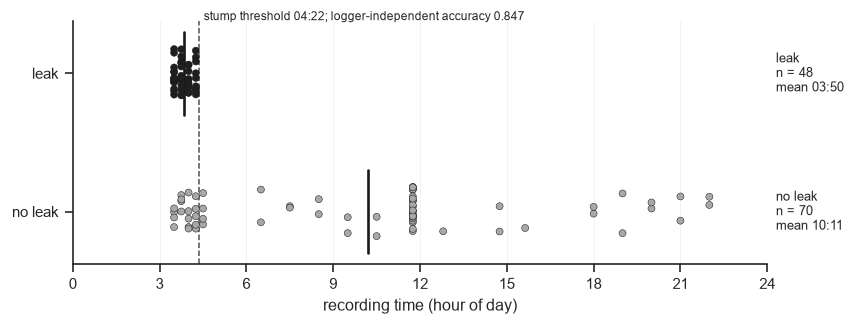

In [4]:
if need("D2_recording_times.csv"):
    t = pd.read_csv(R / "D2_recording_times.csv")
    t["class"] = t.label.map({"leak": "leak", "noleak": "no leak"})
    e6 = json.load(open(R / "E6_time_confound_D2.json"))
    thr = pd.read_csv(R / "E6_time_confound_D2.csv").full_data_threshold_h.iloc[0]
    order = ["leak", "no leak"]
    fig, ax = plt.subplots(figsize=(7.2, 2.8))
    sns.stripplot(data=t, x="hour", y="class", order=order, hue="class", hue_order=order,
                  palette={"leak": G[5], "no leak": G[2]}, jitter=0.18, size=4.2,
                  edgecolor="0.1", linewidth=0.3, legend=False, ax=ax)
    for k, lab in enumerate(order):
        h = t[t["class"] == lab].hour
        ax.plot([h.mean()] * 2, [k - 0.3, k + 0.3], color="0.1", lw=1.6)
        ax.text(24.3, k, f"{lab}\nn = {len(h)}\nmean {int(h.mean()):02d}:{int(round(h.mean() % 1 * 60)):02d}",
                va="center", fontsize=7.5)
    ax.axvline(thr, ls="--", lw=0.9, color="0.3")
    ax.text(thr + 0.15, -0.45, f"stump threshold {int(thr):02d}:{int(round(thr % 1 * 60)):02d}; "
            f"logger-independent accuracy {e6['acc_hour_grouped']:.3f}", fontsize=7, va="top")
    ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 3)); ax.set_xlabel("recording time (hour of day)")
    ax.set_ylabel(""); ax.grid(False, axis="y")
    sns.despine(ax=ax); fig.tight_layout(); cfg.save_figure(fig, "Fig4_D2_recording_time"); plt.show()
    t.to_csv(R / "fig4_data.csv", index=False)

## Figure 5. Variance attribution

(a) D1, three tasks on the same rows, 160 fits each / (b) D2 and D3 (notebook 08c)

saved figures/Fig5_variance_attribution.png and .pdf (600 dpi, greyscale)


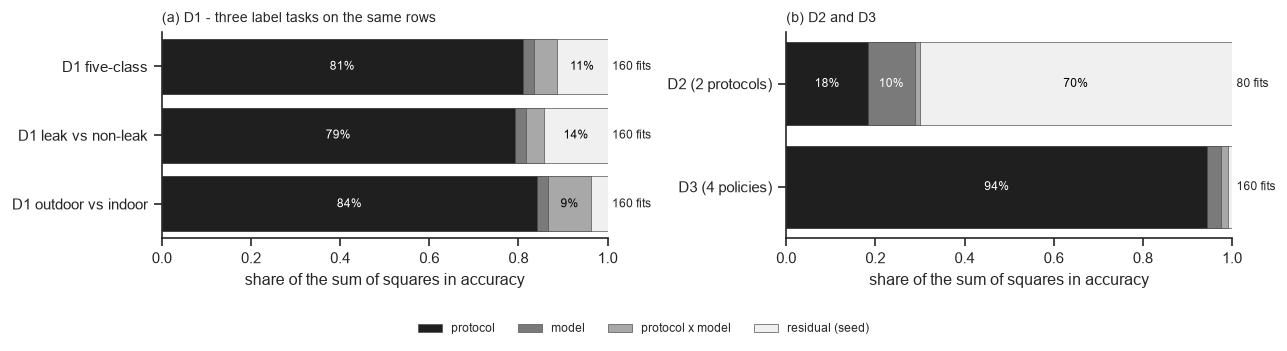

In [5]:
if need("E4_variance_attribution.csv"):
    va = pd.read_csv(R / "E4_variance_attribution.csv")
    vx = pd.read_csv(R / "E4x_variance_attribution_all.csv") if (R / "E4x_variance_attribution_all.csv").exists() else None
    terms = ["protocol", "model", "protocol x model", "residual (seed)"]
    tcol = dict(zip(terms, [G[5], G[3], G[2], G[0]]))
    TN = {"T5_five_class": "D1 five-class", "TL_leak_vs_nonleak": "D1 leak vs non-leak",
          "TR_out_vs_in": "D1 outdoor vs indoor", "D2": "D2 (2 protocols)", "D3": "D3 (4 policies)"}
    panels = [("(a) D1 - three label tasks on the same rows", va.assign(dataset=va.task))]
    if vx is not None:
        v2 = vx[vx.dataset.isin(["D2", "D3"]) & (vx.metric == "acc")]
        if len(v2):
            panels.append(("(b) D2 and D3", v2))
    fig, axes = plt.subplots(1, len(panels), figsize=(5.4 * len(panels), 2.8), squeeze=False)
    for ax, (title, d) in zip(axes[0], panels):
        d = d[d.term.isin(terms)].copy()
        d["label"] = d.dataset.map(lambda x: TN.get(x, x))
        piv = d.pivot(index="label", columns="term", values="ss_share")[terms]
        cum = piv.cumsum(axis=1)
        for term in reversed(terms):                         # draw widest first
            sns.barplot(x=cum[term].values, y=cum.index, orient="h", color=tcol[term],
                        edgecolor="0.3", linewidth=0.4, ax=ax, label=term)
        for j, lab in enumerate(cum.index):
            left = 0
            for term in terms:
                v = piv.loc[lab, term]
                if v > 0.06:
                    ax.text(left + v / 2, j, f"{100*v:.0f}%", ha="center", va="center", fontsize=7,
                            color="white" if term in ("protocol", "model") else "black")
                left += v
            n = int(d[d.label == lab].n_fits.iloc[0])
            ax.text(1.01, j, f"{n} fits", va="center", fontsize=7)
        ax.set_xlim(0, 1); ax.set_xlabel("share of the sum of squares in accuracy"); ax.set_ylabel("")
        ax.set_title(title, loc="left", fontsize=8.5); ax.grid(False)
        h, l = ax.get_legend_handles_labels()
        if ax.get_legend() is not None:
            ax.get_legend().remove()
        sns.despine(ax=ax)
    fig.legend(h[::-1], l[::-1], fontsize=7, loc="lower center", bbox_to_anchor=(0.5, -0.04), ncol=4)
    fig.tight_layout(rect=(0, 0.08, 1, 1)); cfg.save_figure(fig, "Fig5_variance_attribution"); plt.show()
    va.to_csv(R / "fig5_data.csv", index=False)

## Figure 6. D3 split policies (OOF)

- Error bars: bootstrap over physical runs (H1 + H2)
- Dashed line: training-majority rule (0.800); dotted line: BA chance (0.500)

saved figures/Fig6_D3_split_policies.png and .pdf (600 dpi, greyscale)


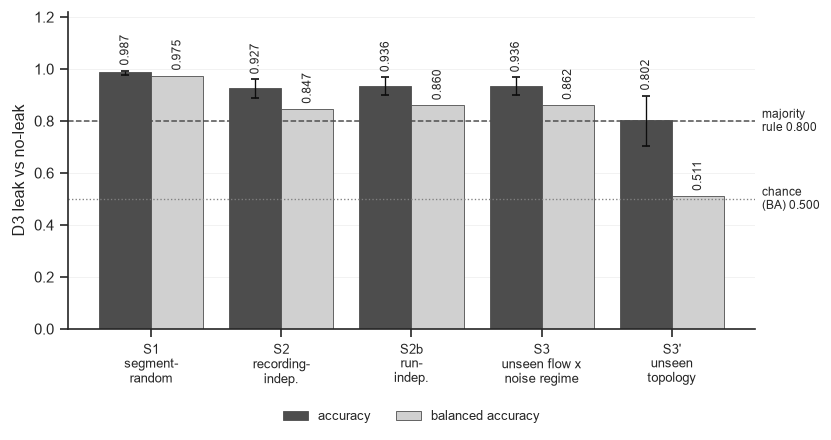

In [6]:
if need("E5_oof_policies.csv"):
    o = pd.read_csv(R / "E5_oof_policies.csv")
    o = o[o.decoding == "pcm32"] if "decoding" in o else o
    PN = {"S1_segment_random": "S1\nsegment-\nrandom", "S2_recording_indep": "S2\nrecording-\nindep.",
          "S2b_run_indep": "S2b\nrun-\nindep.", "S3_opcond_LOCO": "S3\nunseen flow x\nnoise regime",
          "S3_topology_LOTO": "S3'\nunseen\ntopology"}
    o = o.set_index("policy").reindex(list(PN)).reset_index()
    long = o.melt(id_vars=["policy"], value_vars=["acc", "bacc"], var_name="metric", value_name="value")
    long["metric"] = long.metric.map({"acc": "accuracy", "bacc": "balanced accuracy"})
    long["policy_name"] = long.policy.map(PN)
    fig, ax = plt.subplots(figsize=(7.0, 3.8))
    sns.barplot(data=long, x="policy_name", y="value", hue="metric", order=[PN[p] for p in PN],
                palette={"accuracy": G[4], "balanced accuracy": G[1]}, edgecolor="0.3", linewidth=0.5, ax=ax)
    w = ax.patches[0].get_width()
    xs = np.arange(len(o))
    ax.errorbar(xs - w / 2, o.acc, yerr=[o.acc - o.run_boot_lo, o.run_boot_hi - o.acc], fmt="none",
                ecolor="0.05", capsize=2.5, lw=0.8)
    for x_, a, b, top in zip(xs, o.acc, o.bacc, o.run_boot_hi):
        ax.text(x_ - w / 2, max(a, top) + 0.02, f"{a:.3f}", ha="center", fontsize=7, rotation=90, va="bottom")
        ax.text(x_ + w / 2, b + 0.02, f"{b:.3f}", ha="center", fontsize=7, rotation=90, va="bottom")
    ax.axhline(o.rule.iloc[0], ls="--", lw=0.9, color="0.3")
    ax.axhline(0.5, ls=":", lw=0.8, color="0.5")
    yx = ax.get_yaxis_transform()          # x in axes units, y in data units: labels in the right margin
    ax.text(1.01, o.rule.iloc[0], f"majority\nrule {o.rule.iloc[0]:.3f}", transform=yx, ha="left",
            va="center", fontsize=7, clip_on=False)
    ax.text(1.01, 0.5, "chance\n(BA) 0.500", transform=yx, ha="left", va="center", fontsize=7, clip_on=False)
    ax.set_xlabel(""); ax.set_ylabel("D3 leak vs no-leak"); ax.set_ylim(0, 1.22)
    ax.tick_params(axis="x", labelsize=7.5)
    ax.legend(fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, title=None)
    ax.grid(False, axis="x"); sns.despine(ax=ax)
    fig.tight_layout(); cfg.save_figure(fig, "Fig6_D3_split_policies"); plt.show()
    o.drop(columns="cm", errors="ignore").to_csv(R / "fig6_data.csv", index=False)

## Figure A1. D1 structural audit

saved figures/FigA1_structural_audit.png and .pdf (600 dpi, greyscale)


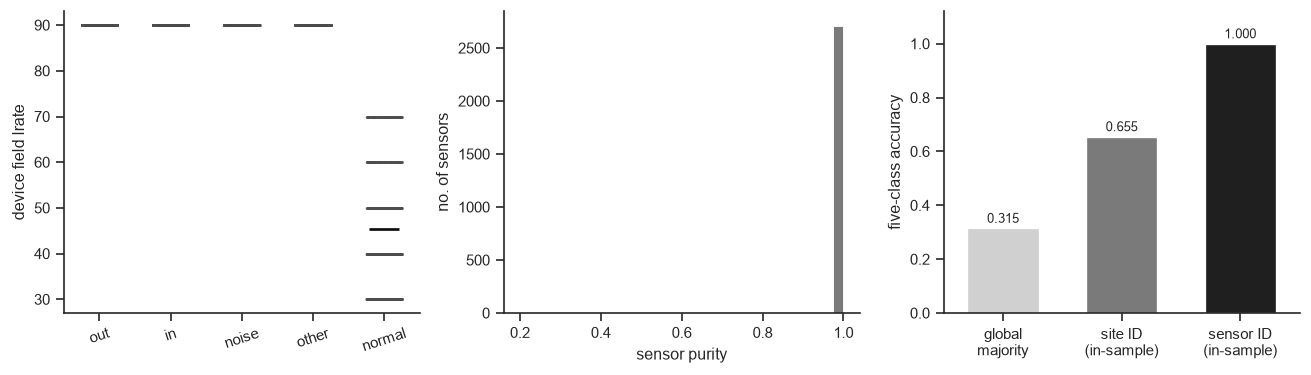

In [7]:
from sklearn.metrics import accuracy_score
X1, X1_max, M1, HZ = io_utils.load_d1()
order = ["out", "in", "noise", "other", "normal"]
samp = M1.sample(frac=1.0, random_state=0).groupby("cls").head(3000)
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
sns.stripplot(data=samp, x="cls", y="lrate", order=order, color=G[4], size=1.5, alpha=0.25,
              jitter=0.25, ax=ax[0], rasterized=True)
sns.pointplot(data=M1, x="cls", y="lrate", order=order, color="0.05", markers="_", markersize=18,
              linestyle="none", errorbar=None, ax=ax[0])
ax[0].set_xlabel(""); ax[0].set_ylabel("device field lrate"); ax[0].tick_params(axis="x", rotation=18)
ct = pd.crosstab(M1.sid, M1.cls); purity = (ct.max(axis=1) / ct.sum(axis=1)).values
sns.histplot(purity, bins=np.linspace(.2, 1., 33), color=G[4], edgecolor=None, ax=ax[1])
ax[1].set_xlabel("sensor purity"); ax[1].set_ylabel("no. of sensors")
maj_sid = M1.groupby("sid").cls.agg(lambda s: s.value_counts().idxmax())
maj_site = M1.groupby("site").cls.agg(lambda s: s.value_counts().idxmax())
bars = pd.DataFrame(dict(predictor=["global\nmajority", "site ID\n(in-sample)", "sensor ID\n(in-sample)"],
                         acc=[M1.cls.value_counts(normalize=True).max(),
                              accuracy_score(M1.cls, M1.site.map(maj_site)),
                              accuracy_score(M1.cls, M1.sid.map(maj_sid))]))
sns.barplot(data=bars, x="predictor", y="acc", hue="predictor", palette=[G[1], G[3], G[5]],
            legend=False, width=0.6, ax=ax[2])
for i, v in enumerate(bars.acc):
    ax[2].text(i, v + .02, f"{v:.3f}", ha="center", fontsize=8)
ax[2].set_ylim(0, 1.12); ax[2].set_xlabel(""); ax[2].set_ylabel("five-class accuracy")
for a in ax:
    a.grid(False); sns.despine(ax=a)
fig.tight_layout(); cfg.save_figure(fig, "FigA1_structural_audit"); plt.show()

## Figure A2. D1 outdoor vs. indoor spectra and per-bin effect size

saved figures/FigA2_out_vs_in_spectra.png and .pdf (600 dpi, greyscale)


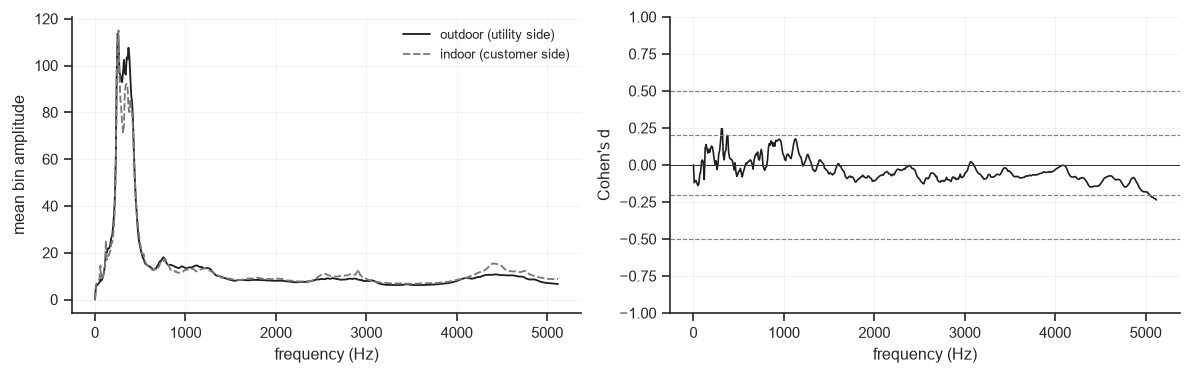

{'max_abs_d': 0.24539558589458466, 'at_hz': 310, 'n_bins_abs_d_ge_0_2': 10, 'n_bins_abs_d_ge_0_5': 0, 'n_bins': 513}


In [8]:
mo = X1[M1.cls.values == "out"].mean(0); mi = X1[M1.cls.values == "in"].mean(0)
so = X1[M1.cls.values == "out"].std(0);  si = X1[M1.cls.values == "in"].std(0)
d = (mo - mi) / (np.sqrt((so**2 + si**2) / 2) + 1e-9)
spec = pd.concat([pd.DataFrame(dict(hz=HZ, amp=mo, cls="outdoor (utility side)")),
                  pd.DataFrame(dict(hz=HZ, amp=mi, cls="indoor (customer side)"))])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
sns.lineplot(data=spec, x="hz", y="amp", hue="cls", style="cls",
             palette=[G[5], G[3]], linewidth=1.1, ax=ax[0])
ax[0].set_xlabel("frequency (Hz)"); ax[0].set_ylabel("mean bin amplitude"); ax[0].legend(fontsize=8, title=None)
sns.lineplot(x=HZ, y=d, color=G[5], linewidth=1.0, ax=ax[1]); ax[1].axhline(0, c="0.2", lw=.6)
for t_ in (.2, .5):
    ax[1].axhline(t_, ls="--", c="0.5", lw=.7); ax[1].axhline(-t_, ls="--", c="0.5", lw=.7)
ax[1].set_ylim(-1, 1); ax[1].set_xlabel("frequency (Hz)"); ax[1].set_ylabel("Cohen's d")
for a in ax:
    sns.despine(ax=a)
fig.tight_layout(); cfg.save_figure(fig, "FigA2_out_vs_in_spectra"); plt.show()
eff = dict(max_abs_d=float(np.abs(d).max()), at_hz=int(HZ[np.abs(d).argmax()]),
           n_bins_abs_d_ge_0_2=int((np.abs(d) >= 0.2).sum()), n_bins_abs_d_ge_0_5=int((np.abs(d) >= 0.5).sum()),
           n_bins=int(len(d)))
print(eff); la.save_json(eff, "FigA2_effect_size.json")
rp.record("D1.out_vs_in.max_abs_cohens_d", eff["max_abs_d"], "FigA2_effect_size.json", "l.425-427 support",
          note=f"at {eff['at_hz']} Hz")

## Figure A3. Accuracy by protocol, all tasks and models

saved figures/FigA3_protocol_dominates_model.png and .pdf (600 dpi, greyscale)


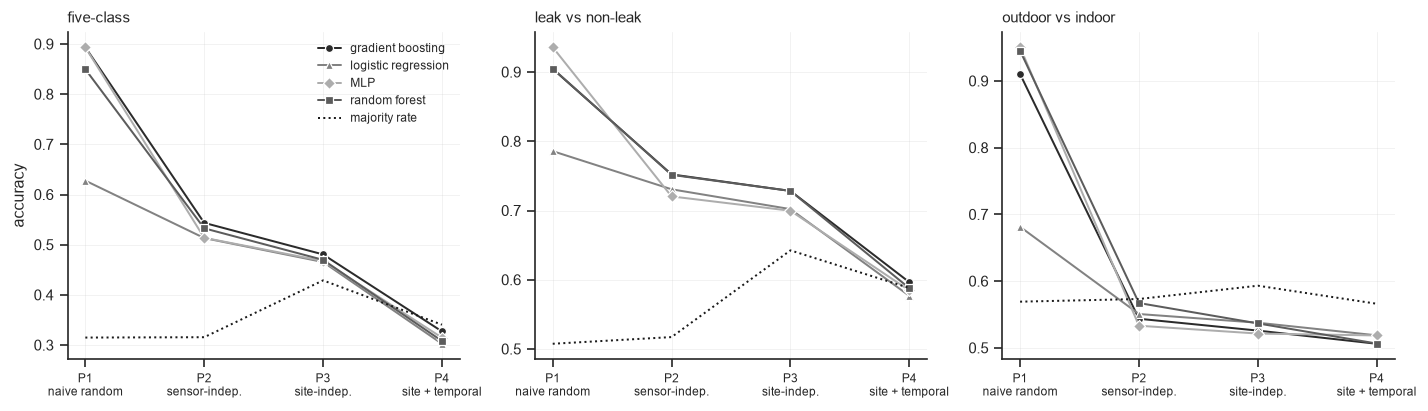

In [9]:
if need("E4_collapse_summary.csv"):
    TN = {"T5_five_class": "five-class", "TL_leak_vs_nonleak": "leak vs non-leak", "TR_out_vs_in": "outdoor vs indoor"}
    s4 = pd.read_csv(R / "E4_collapse_summary.csv")
    s4["model_name"] = s4.model.map(MODEL_NICE)
    s4["x"] = s4.protocol.map({p: i for i, p in enumerate(ev.PROTOCOLS)})
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
    for ax, (t_, lab) in zip(axes, TN.items()):
        sub = s4[s4.task == t_]
        sns.lineplot(data=sub, x="x", y="acc", hue="model_name", style="model_name", markers=MARKERS,
                     dashes=False, palette=MODEL_GREYS, ax=ax, legend=(ax is axes[0]))
        gb = sub[sub.model == "gbdt"].sort_values("x")
        sns.lineplot(x=gb.x, y=gb.base, color="0.1", linestyle=":", ax=ax, label="majority rate" if ax is axes[0] else None)
        ax.set_xticks(range(4)); ax.set_xticklabels([NICE[p] for p in ev.PROTOCOLS], fontsize=7)
        ax.set_xlabel(""); ax.set_ylabel("accuracy" if ax is axes[0] else "")
        ax.set_title(lab, loc="left", fontsize=9); sns.despine(ax=ax)
    axes[0].legend(fontsize=7, title=None)
    fig.tight_layout(); cfg.save_figure(fig, "FigA3_protocol_dominates_model"); plt.show()

## Figure A5. Selective risk vs. acceptance (D1 outdoor vs. indoor, seed 0)

saved figures/FigA5_risk_acceptance.png and .pdf (600 dpi, greyscale)


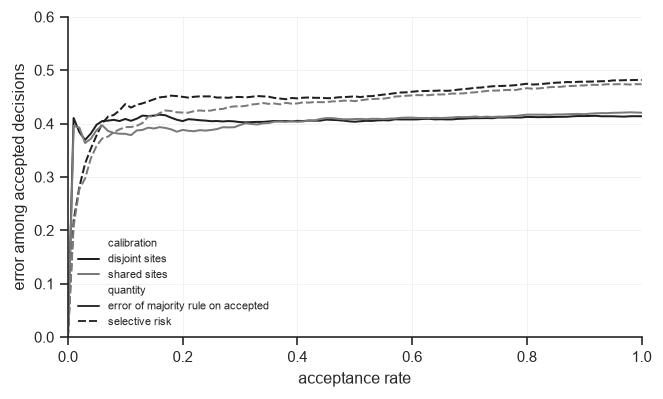

In [10]:
if need("E11b_risk_acceptance_curve.csv"):
    c = pd.read_csv(R / "E11b_risk_acceptance_curve.csv")
    c["calibration"] = c.design.str.replace("_", " ")
    long = pd.concat([c.assign(quantity="selective risk", value=c.selective_risk),
                      c.assign(quantity="error of majority rule on accepted", value=1 - c.baseline_on_accepted)])
    fig, ax = plt.subplots(figsize=(5.6, 3.4))
    sns.lineplot(data=long.sort_values("accept_rate"), x="accept_rate", y="value", hue="calibration",
                 style="quantity", palette=[G[5], G[3]], linewidth=1.2, ax=ax, estimator=None)
    ax.set_xlabel("acceptance rate"); ax.set_ylabel("error among accepted decisions")
    ax.set_xlim(0, 1); ax.set_ylim(0, 0.6); ax.legend(fontsize=6.5); sns.despine(ax=ax)
    fig.tight_layout(); cfg.save_figure(fig, "FigA5_risk_acceptance"); plt.show()

## Figure A6. Identity diagnostics

saved figures/FigA6_identity_diagnostics.png and .pdf (600 dpi, greyscale)


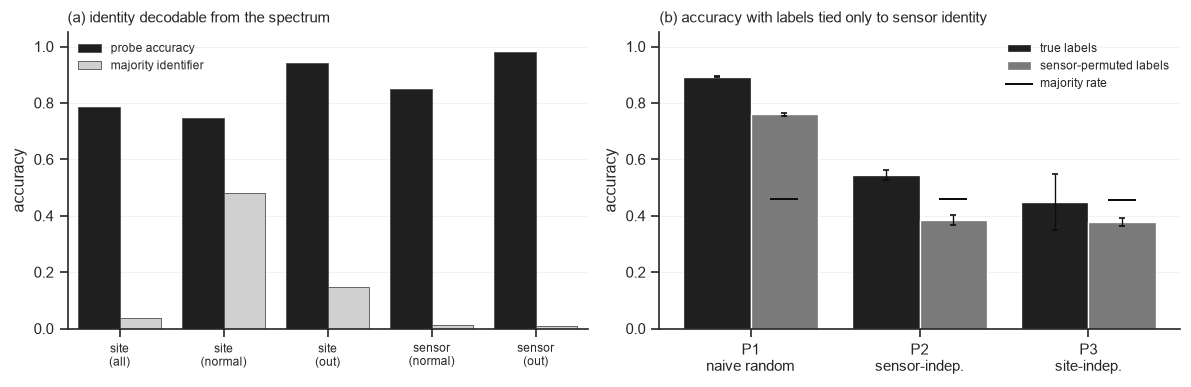

In [11]:
if need("E12_permutation_control_summary.csv") and need("E12_identity_probe.csv"):
    pc = pd.read_csv(R / "E12_permutation_control_summary.csv")
    pr = pd.read_csv(R / "E12_identity_probe.csv")
    pr["target"] = pr.identifier + "\n(" + pr.within_class + ")"
    plong = pr.melt(id_vars="target", value_vars=["acc", "chance"], var_name="q", value_name="v")
    plong["q"] = plong.q.map({"acc": "probe accuracy", "chance": "majority identifier"})
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
    sns.barplot(data=plong, x="target", y="v", hue="q", palette=[G[5], G[1]], edgecolor="0.3",
                linewidth=0.5, ax=ax[0])
    ax[0].set_ylim(0, 1.05); ax[0].set_xlabel(""); ax[0].set_ylabel("accuracy")
    ax[0].tick_params(axis="x", labelsize=7); ax[0].legend(fontsize=7, title=None)
    ax[0].set_title("(a) identity decodable from the spectrum", loc="left", fontsize=9)
    protos = ["P1_naive_random", "P2_sensor_indep", "P3_site_indep"]
    q = pc[pc.protocol.isin(protos)].copy()
    q["labels"] = q.labels.map({"true": "true labels", "sensor_permuted": "sensor-permuted labels"})
    q["proto"] = q.protocol.map(NICE)
    hue_order = ["true labels", "sensor-permuted labels"]
    sns.barplot(data=q, x="proto", y="acc", hue="labels", hue_order=hue_order, order=[NICE[p] for p in protos],
                palette=[G[5], G[3]], ax=ax[1])
    w = ax[1].patches[0].get_width()
    for k, lab in enumerate(hue_order):
        g = q[q["labels"] == lab].set_index("protocol").reindex(protos)
        xs = np.arange(len(protos)) + (k - 0.5) * w
        ax[1].errorbar(xs, g.acc, yerr=g.acc_sd, fmt="none", ecolor="0.05", capsize=2, lw=0.8)
        if lab == "sensor-permuted labels":
            ax[1].scatter(xs, g.base, marker="_", s=300, color="0.05", zorder=4, label="majority rate")
    ax[1].set_ylim(0, 1.05); ax[1].set_xlabel(""); ax[1].set_ylabel("accuracy")
    ax[1].set_title("(b) accuracy with labels tied only to sensor identity", loc="left", fontsize=9)
    ax[1].legend(fontsize=7, title=None)
    for a in ax:
        sns.despine(ax=a)
    fig.tight_layout(); cfg.save_figure(fig, "FigA6_identity_diagnostics"); plt.show()